# Predicting Subscription Renewal Risk and Customer Churn Using Machine Learning

**Notebook 01 — Subscription Churn Prediction**  
**Author:** Trilok Reddy Arava  
**Program:** UC Berkeley Professional Certificate in Machine Learning and Artificial Intelligence  
**Assignment:** Module 24.1 — Final Capstone Project

**Workflow:** Goal → Data Problem → Expected Results → Data Overview → Exploratory Data Analysis → Data Setup → Preprocessing → Model Training → Hyperparameter Tuning → Comparison → Best Model Selection.

**Companion:** [Notebook 02 — Subscription Churn Evaluation](Subscription_Churn_Evaluation.ipynb) focuses on the selected Logistic Regression model and business interpretation.


## Project Overview — Goal, Data Problem, and Expected Results

**Author:** Trilok Reddy Arava  
**Program:** UC Berkeley Professional Certificate in Machine Learning and Artificial Intelligence  
**Assignment:** Module 24.1 — Final Capstone Project

### Executive Summary

This project investigates whether customer, subscription, and billing characteristics can help identify customers at elevated risk of churn. The public IBM Telco Customer Churn dataset contains **7,043 customer records**, of which **1,869 (26.54%)** are labeled as churned. Exploratory analysis identifies differences across contract types, payment methods, tenure, and internet services. The initial **Logistic Regression baseline** achieved **80.55% accuracy**, **55.88% churn recall**, and **0.8419 ROC-AUC** on a held-out test set. The final capstone extends this work by comparing **Naive Bayes, Logistic Regression, Decision Tree, Support Vector Classifier (SVC), and Random Forest**. Predictive associations do **not** establish that a retention intervention causes lower churn.

### Motivation for Choosing This Problem and Dataset

I, As a Senior Engineering Manager working in the Customer Subscription and Renewal Management domain, I am closely involved in the technology and business processes that support subscription lifecycle management and renewals. This professional experience motivated me to select customer churn prediction and subscription renewal risk as the focus of my capstone project.

In subscription-based businesses, understanding why customers may not renew and identifying potential churn risks are important challenges. I wanted to explore how machine learning techniques could help identify customers at higher risk of churn, uncover patterns associated with customer behavior, and provide insights that could support proactive retention strategies.

Since proprietary customer and subscription data from my organization cannot be used for this academic project due to data confidentiality and privacy considerations, I selected the publicly available **IBM Telco Customer Churn dataset**. Although the dataset represents telecommunications customers rather than enterprise software subscriptions, it contains relevant characteristics such as contract types, customer tenure, recurring charges, payment methods, and subscribed services.

This dataset provides a practical opportunity to apply machine learning concepts to a business problem closely related to my professional responsibilities while maintaining appropriate data confidentiality. The objective is to demonstrate the analytical approach and its potential business value, rather than claim that the results directly represent my organization's customers or renewal outcomes.

### Goal

The goal is to identify customers at higher risk of cancellation and determine which of five classification algorithms provides a useful balance of predictive performance, interpretability, and practical retention-team workload. We compare the models using training-only cross-validation and then report performance on the held-out test set. We also examine which subscription characteristics are associated with model predictions.

### Data Problem

This is a **supervised binary classification** task: predict **Churn = Yes** versus **Churn = No** from historical customer information. Inputs include tenure, contract type, subscribed services, monthly and total charges, and payment method. The dataset is moderately imbalanced, so accuracy alone is not sufficient; we examine precision, recall, F1, ROC-AUC, and average precision.

### Expected Results

The intended outcome is a reproducible model comparison, a selected churn-risk classifier, interpretable feature-level findings, and an illustrative customer-risk ranking that could inform a future retention pilot. Performance on these historical telecom records **does not guarantee** accuracy for new customers or for software subscriptions. A real deployment would require prospective validation and controlled experiments to establish whether outreach improves retention.

### Business Rationale

Subscription businesses depend on recurring relationships. Identifying customers at elevated churn risk may help retention teams prioritize limited outreach resources, investigate customer friction, and improve forecasting. Missing a customer who subsequently churns can mean a missed outreach opportunity, while contacting low-risk customers also has a cost.

### Research Question

**Can machine learning identify subscription-based customers at greatest risk of churn and explain the factors associated with that risk, enabling businesses to prioritize retention efforts and improve renewal outcomes?**

### Data — Source and Scope

**Source:** Public IBM Telco Customer Churn dataset, included in this project at [`../data/Telco-Customer-Churn.csv`](../data/Telco-Customer-Churn.csv).

- **Unit of analysis:** One telecom customer record; **7,043 rows** and **21 original columns**.
- **Target:** `Churn` (`Yes` / `No`); **1,869 churned** and **5,174 did not churn**.
- **Predictors:** Demographics and account details, tenure, phone/internet services, contract and billing arrangements, monthly charges, and total charges.
- **Data-quality consideration:** `TotalCharges` contains 11 blank entries that require numeric conversion and missing-value handling.
- **Scope:** This is public **telecom** customer data used as a proxy for subscription renewal risk. It is **not** Salesforce opportunity data, verified SaaS renewal outcomes, or proprietary company information.

### Methodology — CRISP-DM

This project follows **CRISP-DM**: (1) business understanding, (2) data understanding, (3) data preparation, (4) modeling, (5) evaluation, and (6) interpretation and recommendations. This capstone builds on the exploratory data analysis and initial Logistic Regression baseline developed during Module 20, extending the work through four additional classifiers, stratified cross-validation, GridSearchCV tuning, comparative evaluation, and business interpretation. The **80/20 stratified split with `random_state=42`** is retained for comparability.

### What this notebook contains

The sections below walk through data overview and distributions; data cleaning and feature engineering; model setup; **separate code cells for all five classifiers**; evaluation and model selection; summary findings; and business implications. The accompanying evaluation notebook provides individual prediction interpretation, and the README files present technical and nontechnical summaries.


### Notebook Roadmap

**Notebook 01 — Subscription Churn Prediction** covers data understanding, exploratory analysis, cleaning, feature engineering, baseline modeling, five-classifier training and tuning, comparison, model selection, and summary findings. **Notebook 02 — [Subscription Churn Evaluation](Subscription_Churn_Evaluation.ipynb)** covers detailed evaluation of the selected model, customer-level predictions, global and local explanations, and recommendations.

> **Final capstone notebook:** This notebook presents exploratory analysis, the Logistic Regression baseline, and the complete five-model comparison and selection. Detailed interpretation and business recommendations continue in [Notebook 02 — Subscription Churn Evaluation](Subscription_Churn_Evaluation.ipynb). Run from the project root or `notebooks/` directory.

## 1. Setup and reproducibility
I organized this capstone project using a structured directory layout to ensure reproducibility and maintainability.

I used the IBM Telco Customer Churn dataset, which is stored in the project's `data/` directory. I developed and executed the Jupyter notebook from the project directory, with the dataset and generated outputs organized in their respective folders.

To ensure consistent results, I used a fixed random seed (`random_state=42`) for the stratified training and testing split. I also used a preprocessing pipeline to handle missing values, encode categorical variables, and scale numerical features without introducing data leakage.

The analysis outputs, including exploratory visualizations, Logistic Regression baseline evaluation results, and supporting CSV reports, are saved in the `outputs/` directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

sns.set_theme(style="whitegrid")
SEED = 42
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data' / 'Telco-Customer-Churn.csv').exists() else Path.cwd().parent
DATA_FILE = PROJECT_ROOT / 'data' / 'Telco-Customer-Churn.csv'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
REPORT_DIR = PROJECT_ROOT / 'outputs' / 'reports'
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_FILE.exists(), f'Dataset not found: {DATA_FILE}'
print('Project root:', PROJECT_ROOT)
print("Project directory successfully identified.")
print("Dataset location: data/Telco-Customer-Churn.csv")
print("Output directory: outputs/")

Project root: /Users/aravat/Documents/Python/Working/Module_24/Assignment_24_1_Subscription_Churn_Final_Capstone
Project directory successfully identified.
Dataset location: data/Telco-Customer-Churn.csv
Output directory: outputs/


## 2. Data Overview

This section introduces the **raw IBM Telco Customer Churn dataset** before any cleaning or feature engineering. Each inspection task has a separate code cell so that the dataset's size, columns, types, and completeness can be verified independently.

### 2.1 Load the dataset and inspect the first records

In [2]:
raw = pd.read_csv(DATA_FILE)
print(f"Dataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head(10))

Dataset shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


### 2.2 Dataset structure and data types — `info()`

`DataFrame.info()` reports column names, non-null counts, and inferred data types. This is particularly useful because `TotalCharges` initially appears as an object rather than a numeric column.

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 2.3 Column names, descriptive statistics, and missing-value overview

Review numerical summaries, categorical frequencies, missing entries, and blank strings separately. A blank string in `TotalCharges` is not counted as a missing value until it is converted during data cleaning.

In [4]:
print("Column names:")
print(raw.columns.tolist())

print("\nNumerical descriptive statistics:")
display(raw.describe(include="number").T.round(2))

print("\nCategorical descriptive statistics:")
display(raw.describe(include=["str", "object"]).T)

print("\nNull counts by column:")
display(raw.isna().sum().rename("null_count").to_frame())

print("\nBlank TotalCharges strings:")
print(raw["TotalCharges"].astype(str).str.strip().eq("").sum())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.16,0.37,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.37,24.56,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.5,70.35,89.85,118.75



Categorical descriptive statistics:


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095



Null counts by column:


,null_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Blank TotalCharges strings:
11


## 3. Data Distribution

These plots describe **the unmodified source dataset**, before feature engineering or model training. They answer how the target classes are balanced, how numerical variables vary, and how important subscription categories are represented. Later EDA sections explore *relationships with churn* in greater depth.

### 3.1 Target distribution — churn versus non-churn

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


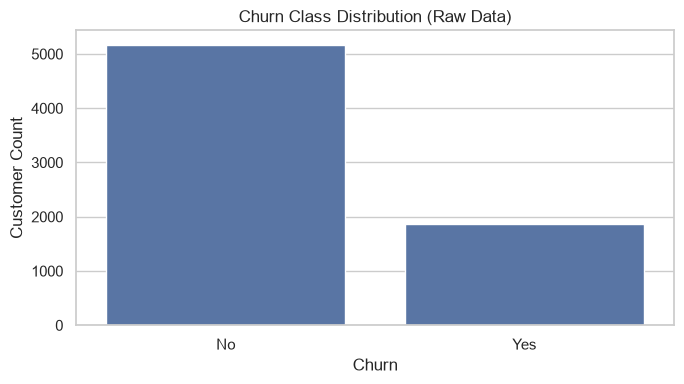

In [5]:
churn_counts = raw['Churn'].value_counts().reindex(['No', 'Yes'])
churn_distribution = pd.DataFrame({'customers': churn_counts, 'percentage': (100 * churn_counts / len(raw)).round(2)})
display(churn_distribution)
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=raw, x='Churn', order=['No', 'Yes'], ax=ax)
ax.set(title='Churn Class Distribution (Raw Data)', xlabel='Churn', ylabel='Customer Count')
plt.tight_layout()
plt.show()

### 3.2 Numerical distributions — tenure, monthly charges, and total charges

Convert `TotalCharges` to numeric in a temporary series **for visualization only**. The source `raw` dataframe is not modified here.

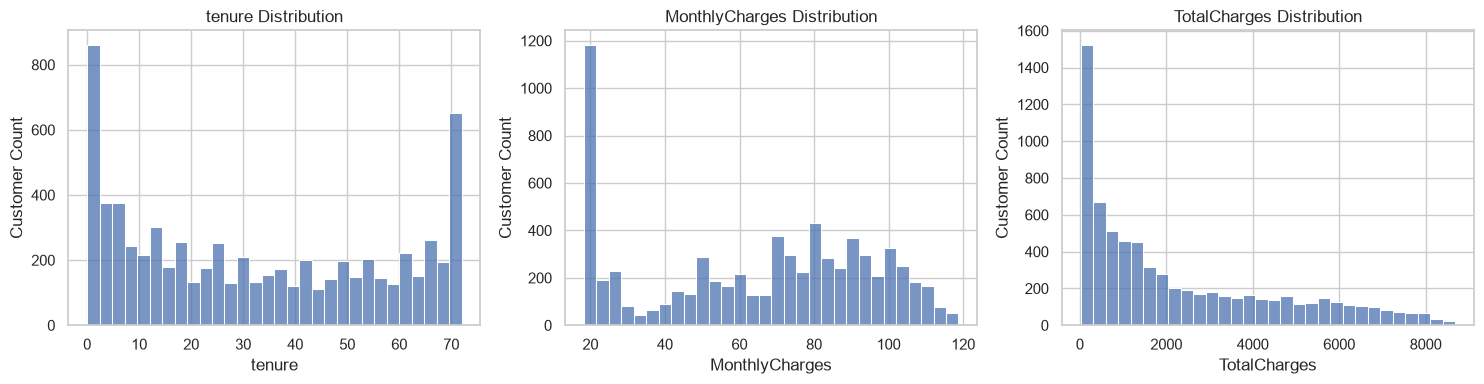

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


In [6]:
distribution_data = raw[['tenure', 'MonthlyCharges']].copy()
distribution_data['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.histplot(distribution_data[column].dropna(), bins=30, ax=ax)
    ax.set(title=f'{column} Distribution', xlabel=column, ylabel='Customer Count')
plt.tight_layout()
plt.show()
display(distribution_data.describe().round(2))

### 3.3 Categorical distributions — contract, internet service, and payment method

These counts show the relative size of major customer groups; they do not yet measure the churn rate within each group.

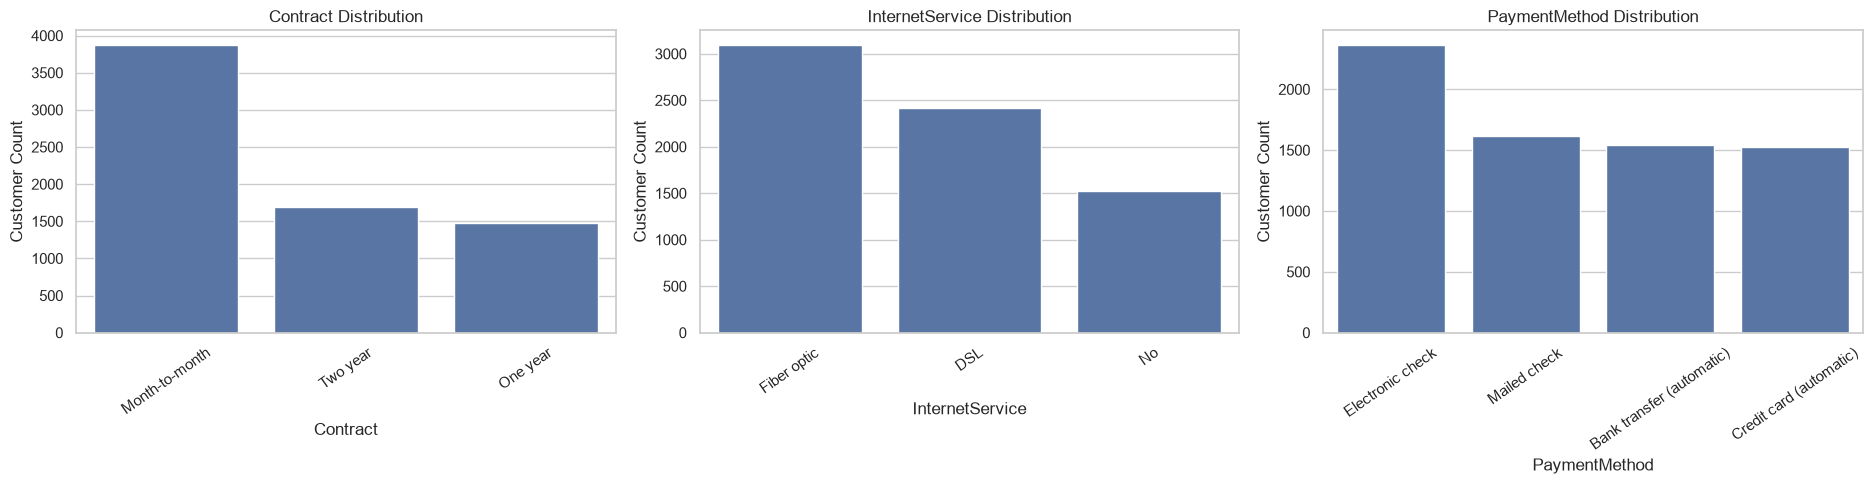

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, column in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    order = raw[column].value_counts().index
    sns.countplot(data=raw, x=column, order=order, ax=ax)
    ax.set(title=f'{column} Distribution', xlabel=column, ylabel='Customer Count')
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

### 3.4 Initial distribution observations

- Check the churn class imbalance before selecting classification metrics; accuracy alone can be misleading.
- Compare tenure and charge distributions for skew and unusual values; investigate rather than automatically remove extreme values.
- Inspect group sizes before interpreting subgroup churn rates, since small groups produce less stable estimates.
- The next section performs the formal quality audit and cleaning; the later EDA examines how these characteristics relate to churn.

## 4. Data Understanding and Quality Audit

The following existing quality checks and subsequent analysis are retained from the earlier notebook.

In [8]:
raw = pd.read_csv(DATA_FILE)
print('Shape:', raw.shape)
display(raw.head())
print('Column types:')
display(raw.dtypes.to_frame('dtype'))
print('Churn counts:')
display(raw['Churn'].value_counts().rename_axis('Churn').to_frame('count'))
print('Duplicate rows:', raw.duplicated().sum())
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print('Raw missing values:', raw.isna().sum().sum())
print('Blank TotalCharges:', raw['TotalCharges'].astype(str).str.strip().eq('').sum())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Column types:


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Churn counts:


,count
Churn,
No,5174
Yes,1869


Duplicate rows: 0
Duplicate customer IDs: 0
Raw missing values: 0
Blank TotalCharges: 11


## 5. Data Cleaning
`TotalCharges` is stored as text and includes blank entries. We convert blanks to missing values. Customer identifiers are excluded from modeling. For rows with missing `TotalCharges`, we retain them and impute **inside the training-only preprocessing pipeline**, avoiding leakage. Duplicate customer IDs, if any, are removed. We do not automatically discard numerical outliers: unusual charges may be legitimate.

In [9]:
# Remove duplicate customer IDs while retaining the original dataset for auditing.
df = raw.drop_duplicates(subset='customerID').copy()
# Convert blank TotalCharges entries to missing numeric values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True), errors='coerce')
# Encode churn as a binary target for classification.
df['ChurnFlag'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
assert df['ChurnFlag'].notna().all()
print('Cleaned shape:', df.shape)
print('Missing values after conversion:')
display(df.isna().sum().loc[lambda s: s.gt(0)].to_frame('missing_count'))
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))

Cleaned shape: (7043, 22)
Missing values after conversion:


,missing_count
TotalCharges,11


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


### Data dictionary and consolidated data-quality audit

The following audit consolidates the data-quality checks without changing the data, features, or baseline. It records the meaning of each source field, its type, missingness, and the treatment applied. The dictionary is saved as a CSV for review in the GitHub repository.

In [10]:
# Document original IBM Telco fields; the target and engineered fields are described separately.
feature_descriptions = {
    'customerID': 'Anonymized customer identifier; excluded from modeling',
    'gender': 'Reported customer gender',
    'SeniorCitizen': 'Senior-citizen indicator (1 = yes)',
    'Partner': 'Whether the customer has a partner',
    'Dependents': 'Whether the customer has dependents',
    'tenure': 'Months the customer has been with the provider',
    'PhoneService': 'Whether phone service is active',
    'MultipleLines': 'Whether multiple phone lines are active',
    'InternetService': 'Internet service category',
    'OnlineSecurity': 'Online security subscription status',
    'OnlineBackup': 'Online backup subscription status',
    'DeviceProtection': 'Device protection subscription status',
    'TechSupport': 'Technical support subscription status',
    'StreamingTV': 'Streaming television subscription status',
    'StreamingMovies': 'Streaming movies subscription status',
    'Contract': 'Subscription contract term',
    'PaperlessBilling': 'Whether paperless billing is enabled',
    'PaymentMethod': 'Customer payment method',
    'MonthlyCharges': 'Current monthly bill amount',
    'TotalCharges': 'Cumulative charges; source includes blank strings',
    'Churn': 'Observed customer churn outcome (Yes or No)'
}
audit_rows = []
for column in raw.columns:
    raw_series = raw[column]
    cleaned_series = df[column] if column in df.columns else raw_series
    audit_rows.append({
        'column': column,
        'description': feature_descriptions.get(column, 'Source field'),
        'raw_dtype': str(raw_series.dtype),
        'cleaned_dtype': str(cleaned_series.dtype),
        'raw_null_count': int(raw_series.isna().sum()),
        'raw_blank_strings': int(raw_series.astype(str).str.strip().eq('').sum()),
        'cleaned_missing_count': int(cleaned_series.isna().sum()),
        'unique_nonmissing_values': int(cleaned_series.nunique(dropna=True)),
        'modeling_treatment': ('Exclude identifier' if column == 'customerID' else
                               'Binary target' if column == 'Churn' else
                               'Numeric conversion + pipeline median imputation' if column == 'TotalCharges' else
                               'Pipeline imputation / encoding or scaling')
    })
data_dictionary = pd.DataFrame(audit_rows)
quality_summary = pd.DataFrame([
    {'check': 'Raw customer records', 'value': len(raw)},
    {'check': 'Duplicate customer IDs', 'value': int(raw.customerID.duplicated().sum())},
    {'check': 'Duplicate complete rows', 'value': int(raw.duplicated().sum())},
    {'check': 'Blank TotalCharges strings', 'value': int(raw.TotalCharges.astype(str).str.strip().eq('').sum())},
    {'check': 'Missing TotalCharges after conversion', 'value': int(df.TotalCharges.isna().sum())},
    {'check': 'Rows after duplicate-ID check', 'value': len(df)},
])
display(quality_summary)
display(data_dictionary[['column','description','cleaned_dtype','cleaned_missing_count','modeling_treatment']])
data_dictionary.to_csv(REPORT_DIR / 'data_dictionary.csv', index=False)
quality_summary.to_csv(REPORT_DIR / 'data_quality_summary.csv', index=False)

,check,value
0,Raw customer records,7043
1,Duplicate customer IDs,0
2,Duplicate complete rows,0
3,Blank TotalCharges strings,11
4,Missing TotalCharges after conversion,11
5,Rows after duplicate-ID check,7043


,column,description,cleaned_dtype,cleaned_missing_count,modeling_treatment
0,customerID,Anonymized customer identifier; excluded from ...,str,0,Exclude identifier
1,gender,Reported customer gender,str,0,Pipeline imputation / encoding or scaling
2,SeniorCitizen,Senior-citizen indicator (1 = yes),int64,0,Pipeline imputation / encoding or scaling
3,Partner,Whether the customer has a partner,str,0,Pipeline imputation / encoding or scaling
4,Dependents,Whether the customer has dependents,str,0,Pipeline imputation / encoding or scaling
5,tenure,Months the customer has been with the provider,int64,0,Pipeline imputation / encoding or scaling
6,PhoneService,Whether phone service is active,str,0,Pipeline imputation / encoding or scaling
7,MultipleLines,Whether multiple phone lines are active,str,0,Pipeline imputation / encoding or scaling
8,InternetService,Internet service category,str,0,Pipeline imputation / encoding or scaling
9,OnlineSecurity,Online security subscription status,str,0,Pipeline imputation / encoding or scaling


**Interpretation:** The `TotalCharges` blank strings represent a data-quality issue, not evidence of zero lifetime spending. Median imputation is learned from each training fold inside the model pipeline. Customer IDs are excluded because they are identifiers rather than behavioral predictors. No observations are dropped solely because `TotalCharges` is missing.

### EDA objectives and interpretation
The following charts compare churn across categorical groups and describe numerical distributions. Group-level churn rates use the number of customers in each group as the denominator; they should not be interpreted as causal effects. The overall churn distribution also reveals class imbalance, motivating stratification and metrics beyond accuracy.


## 6. Exploratory Data Analysis: Distributions and Customer Segments

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


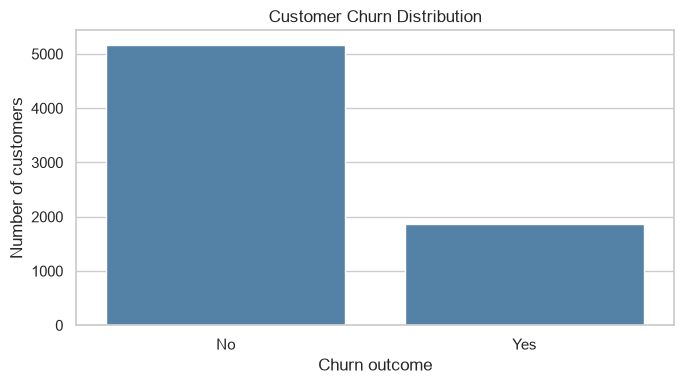

In [11]:
churn_summary = df.groupby('Churn', observed=True).size().rename('customers').to_frame()
churn_summary['percentage'] = (100 * churn_summary['customers'] / len(df)).round(2)
display(churn_summary)
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'], color='steelblue', ax=ax)
ax.set(title='Customer Churn Distribution', xlabel='Churn outcome', ylabel='Number of customers')
fig.tight_layout(); fig.savefig(FIG_DIR / '01_churn_distribution.png', dpi=160); plt.show()

Churn by Contract:


,customers,churn_rate_pct
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


Churn by PaymentMethod:


,customers,churn_rate_pct
PaymentMethod,,
Electronic check,2365,45.29
Mailed check,1612,19.11
Bank transfer (automatic),1544,16.71
Credit card (automatic),1522,15.24


Churn by InternetService:


,customers,churn_rate_pct
InternetService,,
Fiber optic,3096,41.89
DSL,2421,18.96
No,1526,7.40


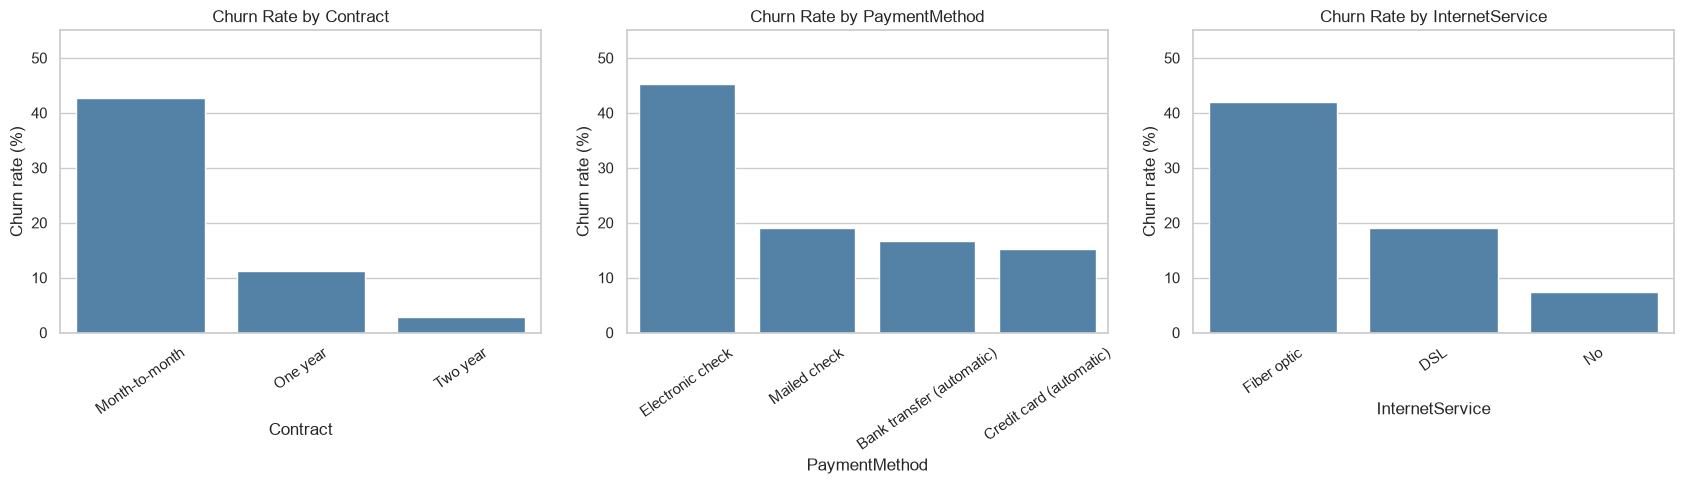

In [12]:
def segment_churn(column):
    return (df.groupby(column, observed=True)['ChurnFlag']
              .agg(customers='size', churn_rate='mean')
              .assign(churn_rate_pct=lambda x: (x.churn_rate * 100).round(2))
              .sort_values('churn_rate', ascending=False))

for col in ['Contract', 'PaymentMethod', 'InternetService']:
    print(f'Churn by {col}:')
    display(segment_churn(col)[['customers', 'churn_rate_pct']])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['Contract', 'PaymentMethod', 'InternetService']):
    s = segment_churn(col)
    sns.barplot(x=s.index.astype(str), y=s['churn_rate_pct'], color='steelblue', ax=ax)
    ax.set(title=f'Churn Rate by {col}', xlabel=col, ylabel='Churn rate (%)', ylim=(0, max(55, s.churn_rate_pct.max() * 1.15)))
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout(); fig.savefig(FIG_DIR / '02_categorical_churn_rates.png', dpi=160, bbox_inches='tight'); plt.show()

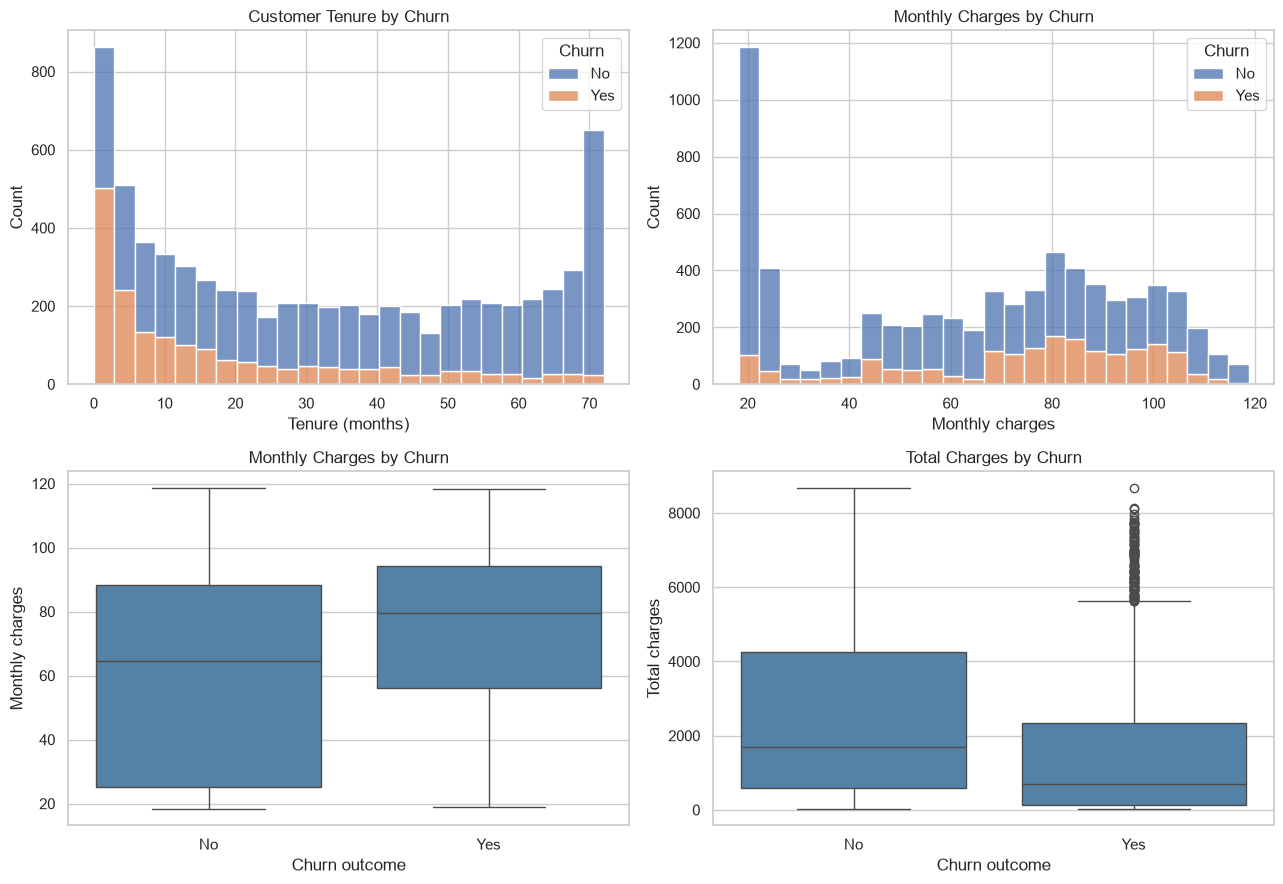

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(data=df, x='tenure', hue='Churn', bins=25, multiple='stack', ax=axes[0, 0])
axes[0, 0].set(title='Customer Tenure by Churn', xlabel='Tenure (months)')
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', bins=25, multiple='stack', ax=axes[0, 1])
axes[0, 1].set(title='Monthly Charges by Churn', xlabel='Monthly charges')
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], color='steelblue', ax=axes[1, 0])
axes[1, 0].set(title='Monthly Charges by Churn', xlabel='Churn outcome', ylabel='Monthly charges')
sns.boxplot(data=df, x='Churn', y='TotalCharges', order=['No', 'Yes'], color='steelblue', ax=axes[1, 1])
axes[1, 1].set(title='Total Charges by Churn', xlabel='Churn outcome', ylabel='Total charges')
fig.tight_layout(); fig.savefig(FIG_DIR / '03_numeric_distributions.png', dpi=160); plt.show()

### Interpretation of numerical distributions
Compare the shapes and spreads of tenure, monthly charges, and total charges across churn outcomes. Because the two classes differ in size, the histogram counts alone do not represent within-group churn probabilities. The boxplots and correlation matrix provide complementary descriptive views, not evidence of causal relationships.


**Additional interpretation:** Compare the *shape and overlap* of tenure and monthly-charge distributions rather than assuming one variable alone determines churn. The plots are descriptive and cannot establish that modifying prices or contract terms would change churn.

## 7. Outlier Analysis and Numeric Relationships
The IQR method flags observations for review, not automatic removal. A low or high charge can be a valid customer observation.

,feature,lower_iqr_bound,upper_iqr_bound,flagged_rows
0,tenure,-60.00,124.00,0
1,MonthlyCharges,-46.02,171.38,0
2,TotalCharges,-4688.48,8884.67,0


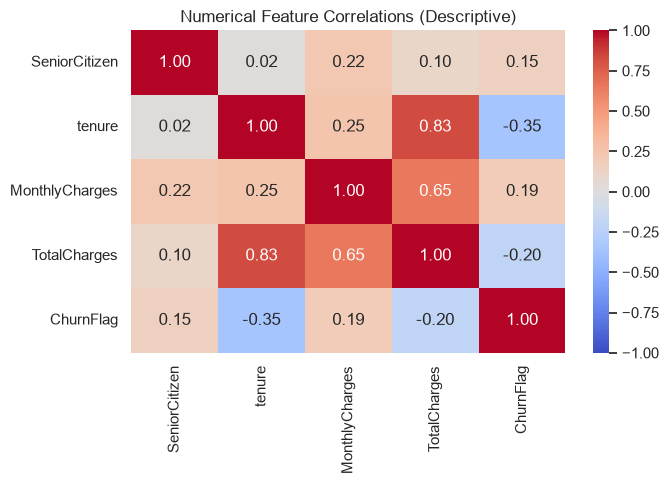

In [14]:
outlier_rows = []
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({'feature': col, 'lower_iqr_bound': lower, 'upper_iqr_bound': upper,
                         'flagged_rows': int(((s < lower) | (s > upper)).sum())})
outliers = pd.DataFrame(outlier_rows)
display(outliers.round(2))
outliers.to_csv(REPORT_DIR / 'outlier_audit.csv', index=False)

corr = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set(title='Numerical Feature Correlations (Descriptive)')
fig.tight_layout(); fig.savefig(FIG_DIR / '04_numeric_correlations.png', dpi=160); plt.show()

### Outlier decision rationale
The interquartile-range (IQR) audit identifies unusually extreme numerical values for inspection. An outlier flag is **not** proof of an error: a high total charge may reflect a long customer relationship. The baseline retains legitimate observations rather than removing them solely on statistical grounds.


## 8. Feature Engineering
We create interpretable customer segments: tenure groups, monthly-charge bands, and a count of subscribed add-on services. Segment boundaries are fixed business-readable bins, not learned from the target. These features are descriptive; some overlap with original predictors, so coefficient interpretation must account for correlated variables.

Churn by TenureGroup:


,customers,churn_rate_pct
TenureGroup,,
0-12 months,2186,47.44
13-24 months,1024,28.71
25-48 months,1594,20.39
49-72 months,2239,9.51


Churn by MonthlyChargeBand:


,customers,churn_rate_pct
MonthlyChargeBand,,
Over $70,3583,35.36
$35-$70,1725,23.94
Under $35,1735,10.89


Churn by AddOnServiceCount:


,customers,churn_rate_pct
AddOnServiceCount,,
1,966,45.76
2,1033,35.82
3,1118,27.37
4,852,22.30
0,2219,21.41
5,571,12.43
6,284,5.28


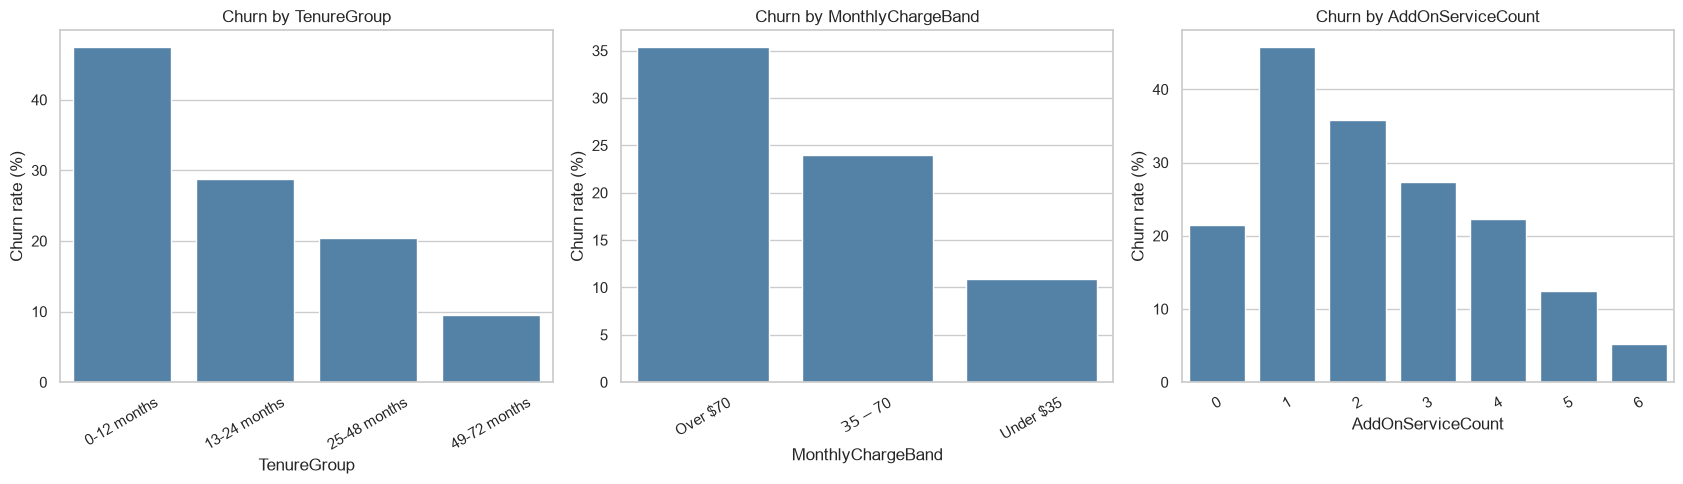

In [15]:
# Create fixed tenure groups to compare churn across customer lifecycles.
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])
# Group monthly charges into interpretable billing bands.
df['MonthlyChargeBand'] = pd.cut(df['MonthlyCharges'], bins=[-np.inf, 35, 70, np.inf], labels=['Under $35', '$35-$70', 'Over $70'])
# Define the optional service columns used in the service-count feature.
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
# Count active add-on services for each customer.
df['AddOnServiceCount'] = df[service_cols].eq('Yes').sum(axis=1)
for col in ['TenureGroup', 'MonthlyChargeBand', 'AddOnServiceCount']:
    print(f'Churn by {col}:')
    display(segment_churn(col)[['customers', 'churn_rate_pct']])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['TenureGroup', 'MonthlyChargeBand', 'AddOnServiceCount']):
    s = segment_churn(col)
    # Display service counts in numeric order; keep other groups in their existing order.
    if col == 'AddOnServiceCount':
        s = s.sort_index()
    sns.barplot(x=s.index.astype(str), y=s['churn_rate_pct'], color='steelblue', ax=ax)
    ax.set(title=f'Churn by {col}', xlabel=col, ylabel='Churn rate (%)')
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(FIG_DIR / '05_engineered_features.png', dpi=160, bbox_inches='tight'); plt.show()

### Feature engineering rationale
**TenureGroup** makes early-versus-long-tenure patterns easier to communicate; **MonthlyChargeBand** summarizes pricing segments; **AddOnServiceCount** aggregates the number of optional services. The first two are used for descriptive EDA, while the service count is included among the baseline predictors. Fixed bins support reproducibility; no target-based feature selection is performed using test outcomes.


**Model-specific preprocessing:** The Logistic Regression and SVC models benefit from standardized numeric features. Tree-based models do not require scaling, but the shared preprocessing pipeline makes comparisons consistent. Gaussian Naive Bayes uses the same engineered inputs converted to a dense matrix. Categorical one-hot encoding is fitted only on training folds to avoid information leakage.

## 9. Baseline Model — Logistic Regression
We use an 80/20 **stratified** split. All imputation, scaling, and categorical encoding are fitted on training data only through a pipeline. We exclude `customerID`, the original text `Churn` column, and `ChurnFlag` from predictors. For a clean baseline, we use original predictor fields plus **AddOnServiceCount**, leaving descriptive tenure and charge bins out of the model to avoid redundant representations. We use the default 0.50 probability threshold and do not tune against the test set.

### Baseline model selection and evaluation rationale
**Why Logistic Regression?** Churn is binary, and Logistic Regression offers an interpretable probability-based benchmark for later models. An **80/20 stratified split** maintains class proportions. Missing-value imputation, numerical scaling, and categorical encoding occur within the fitted training pipeline to reduce leakage risk.

**Metrics:** Accuracy summarizes overall correctness, **precision** measures how many flagged customers actually churn, **recall** measures how many actual churners are found, **F1** balances precision and recall, and **ROC-AUC** evaluates ranking across thresholds. Recall is especially relevant for missed retention opportunities, but precision must also be considered to manage outreach effort. The default decision threshold is 0.50.


In [16]:
# Separate the binary churn target from predictors and exclude identifiers and EDA-only bins.
target = df['ChurnFlag']
features = df.drop(columns=['customerID', 'Churn', 'ChurnFlag', 'TenureGroup', 'MonthlyChargeBand'])
numeric_cols = features.select_dtypes(include=np.number).columns.tolist()
# Use a stratified split to preserve churn proportions in training and test sets.
categorical_cols = features.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.20, stratify=target, random_state=SEED)
# Impute and scale numeric predictors using training-fitted preprocessing.

# Impute and one-hot encode categorical predictors; ignore unseen test categories.
numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))])
# Fit preprocessing and Logistic Regression together on training data only.
preprocessor = ColumnTransformer([('num', numeric_pipe, numeric_cols), ('cat', categorical_pipe, categorical_cols)])
model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))])
# Generate test-set labels and probabilities for baseline evaluation.
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# Evaluate both classification decisions and probability-based ranking metrics.
y_prob = model.predict_proba(X_test)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred),
           'recall': recall_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred),
           'roc_auc': roc_auc_score(y_test, y_prob), 'average_precision': average_precision_score(y_test, y_prob)}
print('Training rows:', len(X_train), 'Test rows:', len(X_test))
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))
pd.DataFrame([{'model': 'Logistic Regression', **metrics}]).to_csv(REPORT_DIR / 'baseline_metrics.csv', index=False)

Training rows: 5634 Test rows: 1409


,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.8055,0.6572,0.5588,0.604,0.8419,0.6334


              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## 10. Baseline Model Evaluation

Evaluate the **initial Logistic Regression baseline** on the held-out test set using the confusion matrix, ROC curve, precision–recall curve, and classification metrics. These results are a benchmark; they do not determine the best model in the later five-model comparison.

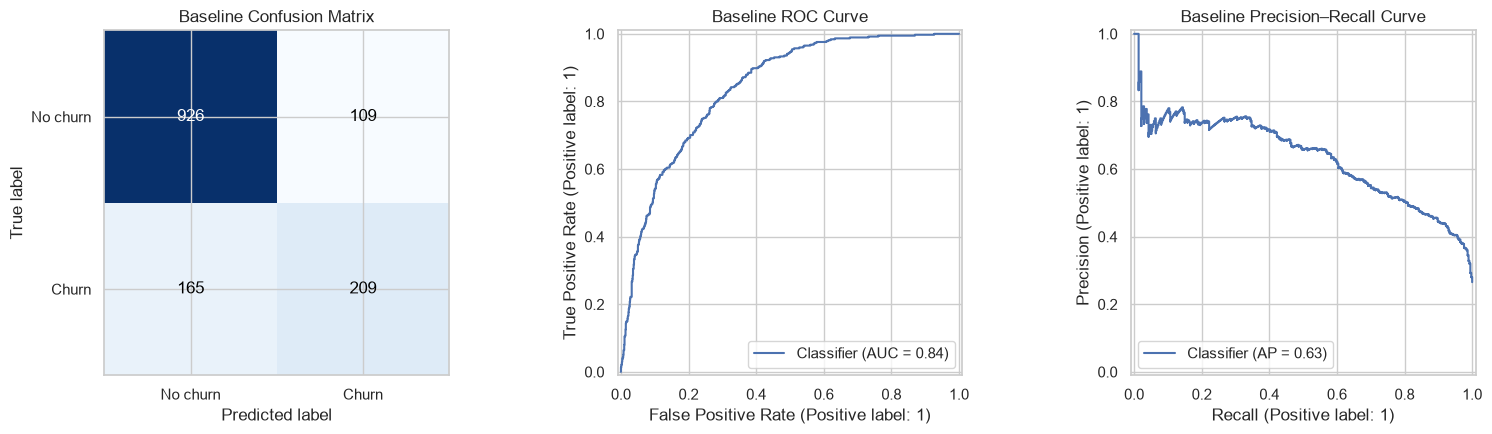

In [17]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# Create three plots in a single row
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Confusion Matrix
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No churn", "Churn"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0]
)

axes[0].set_title("Baseline Confusion Matrix")

# Improve annotation contrast based on background color
for text, value in zip(cm_display.text_.ravel(), cm_display.confusion_matrix.ravel()):
    text.set_color("white" if value > cm_display.confusion_matrix.max() / 2 else "black")

# 2. ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[1]
)
axes[1].set_title("Baseline ROC Curve")

# 3. Precision–Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=axes[2]
)
axes[2].set_title("Baseline Precision–Recall Curve")

# Adjust spacing and save the updated figure
fig.tight_layout()

fig.savefig(
    FIG_DIR / "06_baseline_evaluation.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### Baseline evaluation — what the confusion matrix means
On the held-out test set, the model produced **926 true negatives**, **109 false positives**, **165 false negatives**, and **209 true positives**. It therefore detected **209 of 374** actual churners (**55.88% recall**), while missing 165. The ROC and precision–recall curves illustrate threshold-dependent tradeoffs; the current results are a baseline, not a production-ready decision policy.

#### Evaluation Metric Selection and Rationale

I selected **churn recall as my primary evaluation metric** because my business objective is to identify as many customers at risk of churn as possible before they leave. A higher recall helps reduce false negatives—customers who actually churn but are not identified by the model.

I also evaluate **precision** to understand the potential cost of unnecessary retention outreach and **ROC-AUC** to assess the model’s ability to distinguish churners from non-churners across classification thresholds.

My Logistic Regression baseline achieved **55.88% churn recall**, **65.72% precision**, and **0.8419 ROC-AUC** on the held-out test set. These results provide a benchmark for the five-model comparison and further research.


## 11. Interpreting Baseline Logistic Regression Associations
Logistic Regression coefficients describe associations with predicted churn **conditional on other encoded predictors**, not causal effects. One-hot encoded categories are compared to other categories within the representation; correlated features can make individual coefficients unstable.

,feature,coefficient,abs_coefficient
1,num__tenure,-1.240,1.240
39,cat__Contract_Two year,-0.774,0.774
16,cat__InternetService_DSL,-0.684,0.684
17,cat__InternetService_Fiber optic,0.647,0.647
2,num__MonthlyCharges,-0.641,0.641
37,cat__Contract_Month-to-month,0.579,0.579
3,num__TotalCharges,0.515,0.515
40,cat__PaperlessBilling_No,-0.345,0.345
35,cat__StreamingMovies_No internet service,-0.281,0.281
32,cat__StreamingTV_No internet service,-0.281,0.281


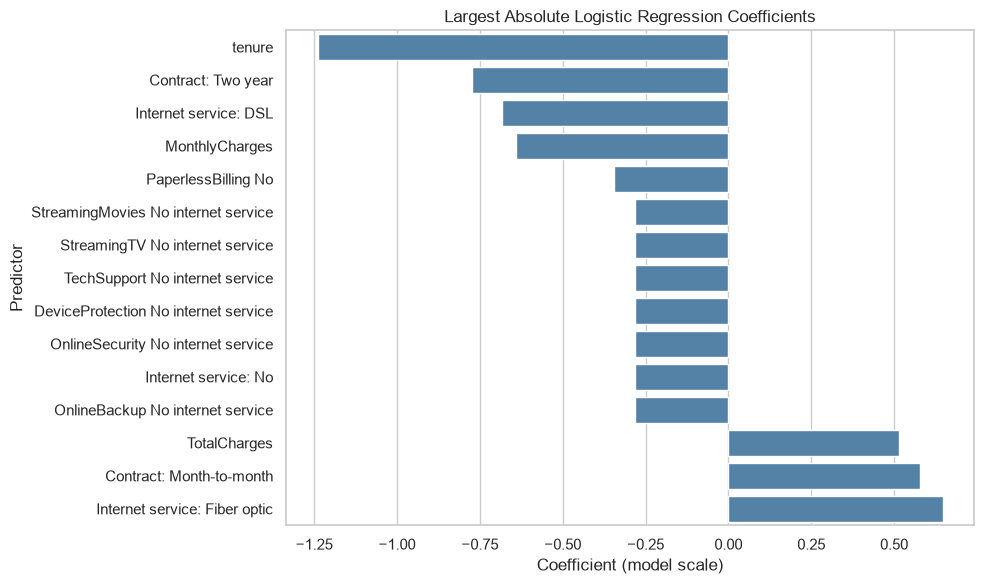

In [18]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
coefficients = pd.DataFrame({'feature': feature_names, 'coefficient': model.named_steps['classifier'].coef_[0]})
coefficients['abs_coefficient'] = coefficients['coefficient'].abs()
coefficients = coefficients.sort_values('abs_coefficient', ascending=False)
display(coefficients.head(15).round(3))
coefficients.to_csv(REPORT_DIR / 'baseline_coefficients.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = coefficients.head(15).sort_values('coefficient').copy()
# Format encoded feature names for display only; retain original names in the CSV report.
def readable_feature_name(name):
    name = name.removeprefix('num__').removeprefix('cat__')
    name = name.replace('InternetService_', 'Internet service: ')
    name = name.replace('Contract_', 'Contract: ')
    name = name.replace('_', ' ')
    return name

plot_data['display_feature'] = plot_data['feature'].map(readable_feature_name)
sns.barplot(data=plot_data, x='coefficient', y='display_feature', color='steelblue', ax=ax)
ax.set(title='Largest Absolute Logistic Regression Coefficients', xlabel='Coefficient (model scale)', ylabel='Predictor')
fig.tight_layout(); fig.savefig(FIG_DIR / '07_model_coefficients.png', dpi=160, bbox_inches='tight'); plt.show()

In [19]:
from pathlib import Path

print("Figures:")
for file in sorted(FIG_DIR.glob("*.png")):
    print("✓", file.name)

print("\nReports:")
for file in sorted(REPORT_DIR.glob("*.csv")):
    print("✓", file.name)

Figures:
✓ 01_churn_distribution.png
✓ 02_categorical_churn_rates.png
✓ 03_numeric_distributions.png
✓ 04_numeric_correlations.png
✓ 05_engineered_features.png
✓ 06_baseline_evaluation.png
✓ 07_model_coefficients.png

Reports:
✓ baseline_coefficients.csv
✓ baseline_metrics.csv
✓ data_dictionary.csv
✓ data_quality_summary.csv
✓ outlier_audit.csv


---

# Model Training, Hyperparameter Tuning, and Comparison

This section trains, tunes, and compares Naive Bayes, Logistic Regression, Decision Tree, SVC, and Random Forest using separate pipelines. Like the Berkeley sample, it compares candidates and selects a winner **before** the separate interpretation notebook.

**Note:** The initial Logistic Regression baseline above is retained for comparison. The five-model comparison below reinitializes a consistent data setup to support reproducibility.


## Setup and Data Preparation

### Data Overview and Data Setup

The data is set up, split, and preprocessed using the same process as before. All imputation, scaling, and encoding are fitted within each training fold to avoid leakage. The original 80/20 stratified split with `random_state=42` is retained.

In [20]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
import joblib
SEED=42
ROOT=Path.cwd() if (Path.cwd()/'data'/'Telco-Customer-Churn.csv').exists() else Path.cwd().parent
DATA=ROOT/'data'/'Telco-Customer-Churn.csv'; FIG=ROOT/'outputs'/'figures'; REPORT=ROOT/'outputs'/'reports'
FIG.mkdir(parents=True,exist_ok=True); REPORT.mkdir(parents=True,exist_ok=True)
assert DATA.exists(),f'Missing data: {DATA}'
sns.set_theme(style='whitegrid')
raw=pd.read_csv(DATA)
df=raw.drop_duplicates(subset='customerID').copy()
df['TotalCharges']=pd.to_numeric(df['TotalCharges'].replace(r'^\s*$',np.nan,regex=True),errors='coerce')
df['ChurnFlag']=df['Churn'].map({'No':0,'Yes':1}).astype(int)
df['TenureGroup']=pd.cut(df['tenure'],bins=[-1,12,24,48,72],labels=['0-12 months','13-24 months','25-48 months','49-72 months'])
df['MonthlyChargeBand']=pd.cut(df['MonthlyCharges'],bins=[-np.inf,35,70,np.inf],labels=['Under $35','$35-$70','Over $70'])
service_cols=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
df['AddOnServiceCount']=df[service_cols].eq('Yes').sum(axis=1)
y=df['ChurnFlag'];X=df.drop(columns=['customerID','Churn','ChurnFlag','TenureGroup','MonthlyChargeBand'])
num=X.select_dtypes(include=np.number).columns.tolist(); cat=X.select_dtypes(exclude=np.number).columns.tolist()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
pre=ColumnTransformer([('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
print('Dataset:',X.shape,'Train:',X_train.shape,'Test:',X_test.shape,'Churn rate:',round(y.mean(),4))
import sys
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from capstone_utils import to_dense


Dataset: (7043, 20) Train: (5634, 20) Test: (1409, 20) Churn rate: 0.2654


## Model Training

We compare **five classifiers**: Naive Bayes, Logistic Regression, Decision Tree, Support Vector Classifier (SVC), and Random Forest. Each uses the same data, preprocessing pipeline, 3-fold stratified cross-validation, and GridSearchCV. **Average precision** is the primary training-only model-selection metric because churn is the minority class. ROC-AUC, recall, F1, precision, and accuracy provide additional context.

### Naive Bayes Model
Gaussian Naive Bayes is a probabilistic baseline. One-hot encoded categories are converted to a dense matrix before fitting; its conditional independence and Gaussian assumptions are approximations.

### Logistic Regression Model
This is the baseline algorithm family. We tune regularization strength and class weighting while retaining the initial baseline results earlier in this notebook.

### Decision Tree Model
A transparent nonlinear classifier. We tune maximum depth, minimum leaf size, and class weighting to reduce overfitting.

### Support Vector Classifier Model
An SVC with a linear kernel is tuned for regularization and class weighting. A calibrated classifier provides probability estimates for average precision, ROC-AUC, and customer-risk scoring.

### Random Forest Model (Additional)
An ensemble of trees, included beyond the four sample models. We tune depth and class weighting.

### Hyperparameter Search and Cross-Validation
All model search and selection occur **on the training set only**. The untouched test set is used once to describe final generalization performance at the prespecified 0.50 threshold.

### Why these five classifiers?

The four classifiers from Berkeley Sample Project 1 are included alongside Random Forest. All five use the **same stratified train/test partition**. Preprocessing and tuning are fitted on training folds only.

#### Naive Bayes Model
Gaussian Naive Bayes offers a fast probabilistic baseline. Its conditional-independence and distribution assumptions may not perfectly match one-hot encoded subscription features.

#### Logistic Regression Model
The initial Logistic Regression baseline is retained earlier in this notebook. GridSearchCV explores regularization strength and class weighting; the final tuned comparison may or may not select different parameters.

#### Decision Tree Model
A readable nonlinear model; tree depth, leaf size, and class weighting control overfitting and minority-class sensitivity.

#### Support Vector Classifier Model
A linear-kernel margin-based model; probability estimates enable ROC-AUC and average precision comparisons. Standardized numeric features help the optimization.

#### Random Forest Model
An ensemble of decision trees intended to reduce variance compared with a single tree. We include it as an extension beyond the sample project.

**Model selection:** We choose the highest *training-only cross-validation average precision*; held-out test results are used to describe performance, not to pick a winner. The model grid is intentionally bounded for reproducible execution.

### Hyperparameter tuning and validation design

Each candidate pipeline is evaluated using stratified three-fold cross-validation. GridSearchCV refits the candidate with the highest mean average precision on the full training split. Accuracy, precision, recall, F1, ROC-AUC, and average precision are reported on the untouched test split at the same 0.50 threshold. Average precision is emphasized because churn is the minority class and the business may act on a ranked list of high-risk customers.

**Tradeoff:** High recall catches more actual churners but can require contacting more customers who would have stayed. High precision conserves outreach capacity but may miss churners.

In [21]:
# Shared evaluation setup. The held-out test set is not used to choose hyperparameters.
from sklearn.preprocessing import FunctionTransformer
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scoring = {'average_precision': 'average_precision', 'roc_auc': 'roc_auc',
           'recall': 'recall', 'f1': 'f1'}
cv_rows, test_rows, predictions, best_estimators = [], [], [], {}

def record_model(name, search):
    """Record CV and holdout scores for a completed model search."""
    best = search.best_estimator_
    best_estimators[name] = best
    probabilities = best.predict_proba(X_test)[:, 1]
    labels = (probabilities >= 0.50).astype(int)
    best_idx = search.best_index_
    cv_rows.append({
        'model': name, 'cv_average_precision': search.best_score_,
        'cv_roc_auc': search.cv_results_['mean_test_roc_auc'][best_idx],
        'cv_recall': search.cv_results_['mean_test_recall'][best_idx],
        'cv_f1': search.cv_results_['mean_test_f1'][best_idx],
        'best_params': str(search.best_params_)
    })
    test_rows.append({
        'model': name, 'accuracy': accuracy_score(y_test, labels),
        'precision': precision_score(y_test, labels, zero_division=0),
        'recall': recall_score(y_test, labels), 'f1': f1_score(y_test, labels),
        'roc_auc': roc_auc_score(y_test, probabilities),
        'average_precision': average_precision_score(y_test, probabilities)
    })
    predictions.append(pd.DataFrame({
        'row_index': X_test.index, 'actual': y_test.values,
        'model': name, 'probability': probabilities, 'prediction_0_5': labels
    }))
    print('Best parameters:', search.best_params_)
    print('CV average precision:', round(search.best_score_, 4))
    display(pd.DataFrame([test_rows[-1]]).round(4))


### Naive Bayes Model

Gaussian Naive Bayes provides a probabilistic comparison. It requires dense numeric features; the pipeline converts the encoded data to dense format.

The following cells explicitly define the preprocessing pipeline, tune hyperparameters with **GridSearchCV on training folds**, display the best parameters, and report held-out metrics. The held-out metrics are descriptive, not used for tuning.

In [22]:
# Naive Bayes: pipeline and parameter grid
nb_pipeline = Pipeline([
    ('preprocessor', pre),
    ('to_dense', FunctionTransformer(to_dense, accept_sparse=True)),
    ('classifier', GaussianNB())
])
nb_params = {"classifier__var_smoothing": [1e-9, 1e-7]}
print('Parameter grid:', nb_params)

Parameter grid: {'classifier__var_smoothing': [1e-09, 1e-07]}


In [23]:
# Naive Bayes: cross-validated hyperparameter search
nb_grid = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=nb_params,
    scoring=scoring,
    refit='average_precision',
    cv=cv,
    n_jobs=1,
    error_score='raise'
)
nb_grid.fit(X_train, y_train)
record_model('Naive Bayes', nb_grid)

Best parameters: {'classifier__var_smoothing': 1e-09}
CV average precision: 0.6134


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Naive Bayes,0.6927,0.4567,0.8316,0.5896,0.807,0.5846


### Logistic Regression Model

This is the baseline model family. We retain its initial baseline evaluation earlier in this notebook and tune regularization and class weights here.

The following cells explicitly define the preprocessing pipeline, tune hyperparameters with **GridSearchCV on training folds**, display the best parameters, and report held-out metrics. The held-out metrics are descriptive, not used for tuning.

In [24]:
# Logistic Regression: pipeline and parameter grid
lr_pipeline = Pipeline([
    ('preprocessor', pre),
    ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))
])
lr_params = {"classifier__C": [0.1, 1], "classifier__class_weight": [None, "balanced"]}
print('Parameter grid:', lr_params)

Parameter grid: {'classifier__C': [0.1, 1], 'classifier__class_weight': [None, 'balanced']}


In [25]:
# Logistic Regression: cross-validated hyperparameter search
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring=scoring,
    refit='average_precision',
    cv=cv,
    n_jobs=1,
    error_score='raise'
)
lr_grid.fit(X_train, y_train)
record_model('Logistic Regression', lr_grid)

Best parameters: {'classifier__C': 1, 'classifier__class_weight': None}
CV average precision: 0.6602


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.8055,0.6572,0.5588,0.604,0.8419,0.6334


### Decision Tree Model

A decision tree learns nonlinear splits. Depth, minimum leaf size and class weighting are tuned to control overfitting.

The following cells explicitly define the preprocessing pipeline, tune hyperparameters with **GridSearchCV on training folds**, display the best parameters, and report held-out metrics. The held-out metrics are descriptive, not used for tuning.

In [26]:
# Decision Tree: pipeline and parameter grid
dt_pipeline = Pipeline([
    ('preprocessor', pre),
    ('classifier', DecisionTreeClassifier(random_state=SEED))
])
dt_params = {"classifier__max_depth": [3, 8], "classifier__min_samples_leaf": [10], "classifier__class_weight": [None, "balanced"]}
print('Parameter grid:', dt_params)

Parameter grid: {'classifier__max_depth': [3, 8], 'classifier__min_samples_leaf': [10], 'classifier__class_weight': [None, 'balanced']}


In [27]:
# Decision Tree: cross-validated hyperparameter search
dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_params,
    scoring=scoring,
    refit='average_precision',
    cv=cv,
    n_jobs=1,
    error_score='raise'
)
dt_grid.fit(X_train, y_train)
record_model('Decision Tree', dt_grid)

Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10}
CV average precision: 0.5903


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Decision Tree,0.7793,0.5782,0.623,0.5997,0.8048,0.6026


### Support Vector Classifier Model

A linear-kernel SVC learns a separating boundary. Probability estimation is enabled for average precision, ROC-AUC and risk scoring.

The following cells explicitly define the preprocessing pipeline, tune hyperparameters with **GridSearchCV on training folds**, display the best parameters, and report held-out metrics. The held-out metrics are descriptive, not used for tuning.

In [28]:
from sklearn.calibration import CalibratedClassifierCV

# Support Vector Classifier: pipeline and parameter grid
svc_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CalibratedClassifierCV(
        estimator=SVC(kernel="linear", random_state=SEED),
        method="sigmoid",
        cv=3,
        ensemble=False
    ))
])

svc_params = {
    "classifier__estimator__C": [0.1],
    "classifier__estimator__class_weight": [None]
}

print("Parameter grid:", svc_params)


Parameter grid: {'classifier__estimator__C': [0.1], 'classifier__estimator__class_weight': [None]}


In [29]:
# Support Vector Classifier: cross-validated hyperparameter search
svc_grid = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=svc_params,
    scoring=scoring,
    refit='average_precision',
    cv=cv,
    n_jobs=1,
    error_score='raise'
)
svc_grid.fit(X_train, y_train)
record_model('Support Vector Classifier', svc_grid)

Best parameters: {'classifier__estimator__C': 0.1, 'classifier__estimator__class_weight': None}
CV average precision: 0.6494


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Support Vector Classifier,0.7949,0.6421,0.5134,0.5706,0.8266,0.6211


### Random Forest Model

Random Forest combines trees to reduce the variance of a single decision tree.

The following cells explicitly define the preprocessing pipeline, tune hyperparameters with **GridSearchCV on training folds**, display the best parameters, and report held-out metrics. The held-out metrics are descriptive, not used for tuning.

In [30]:
# Random Forest: pipeline and parameter grid
rf_pipeline = Pipeline([
    ('preprocessor', pre),
    ('classifier', RandomForestClassifier(n_estimators=30, random_state=SEED, n_jobs=1))
])
rf_params = {"classifier__max_depth": [6], "classifier__min_samples_leaf": [5], "classifier__class_weight": [None, "balanced"]}
print('Parameter grid:', rf_params)

Parameter grid: {'classifier__max_depth': [6], 'classifier__min_samples_leaf': [5], 'classifier__class_weight': [None, 'balanced']}


In [31]:
# Random Forest: cross-validated hyperparameter search
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring=scoring,
    refit='average_precision',
    cv=cv,
    n_jobs=1,
    error_score='raise'
)
rf_grid.fit(X_train, y_train)
record_model('Random Forest', rf_grid)

Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5}
CV average precision: 0.6526


,model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Random Forest,0.7999,0.6691,0.4866,0.5635,0.8394,0.6502


### Consolidated cross-validation and test results

Each model was tuned separately above. We now assemble the results and save the same filenames used by Notebook 03. Model selection uses **training-only cross-validation average precision**.

In [32]:
cv_results = pd.DataFrame(cv_rows).sort_values('cv_average_precision', ascending=False)
test_results = pd.DataFrame(test_rows).sort_values('average_precision', ascending=False)
cv_results.to_csv(REPORT / 'cross_validation_results.csv', index=False)
test_results.to_csv(REPORT / 'final_model_comparison.csv', index=False)
pd.concat(predictions, ignore_index=True).to_csv(REPORT / 'test_predictions.csv', index=False)
for name, estimator in best_estimators.items():
    joblib.dump(estimator, REPORT / ('model_' + name.lower().replace(' ', '_') + '.joblib'))
selected = cv_results.iloc[0]['model']
(REPORT / 'selected_model.txt').write_text(selected + '\n')
print('Training cross-validation:')
display(cv_results.round(4))
print('Held-out test results:')
display(test_results.round(4))
print('Selected by training CV:', selected)

Training cross-validation:


,model,cv_average_precision,cv_roc_auc,cv_recall,cv_f1,best_params
1,Logistic Regression,0.6602,0.8458,0.5445,0.5945,"{'classifier__C': 1, 'classifier__class_weight..."
4,Random Forest,0.6526,0.8433,0.4702,0.5554,"{'classifier__class_weight': None, 'classifier..."
3,Support Vector Classifier,0.6494,0.8342,0.5171,0.5817,"{'classifier__estimator__C': 0.1, 'classifier_..."
0,Naive Bayes,0.6134,0.8202,0.8462,0.5979,{'classifier__var_smoothing': 1e-09}
2,Decision Tree,0.5903,0.8012,0.5244,0.5584,"{'classifier__class_weight': None, 'classifier..."


Held-out test results:


,model,accuracy,precision,recall,f1,roc_auc,average_precision
4,Random Forest,0.7999,0.6691,0.4866,0.5635,0.8394,0.6502
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419,0.6334
3,Support Vector Classifier,0.7949,0.6421,0.5134,0.5706,0.8266,0.6211
2,Decision Tree,0.7793,0.5782,0.6230,0.5997,0.8048,0.6026
0,Naive Bayes,0.6927,0.4567,0.8316,0.5896,0.8070,0.5846


Selected by training CV: Logistic Regression


## Model Evaluation and Summary of Results

The following charts compare the five tuned models on the untouched test set. Confusion matrices show false negatives and false positives for each classifier. **Do not choose the winning model using the test charts**; use training-only CV average precision.

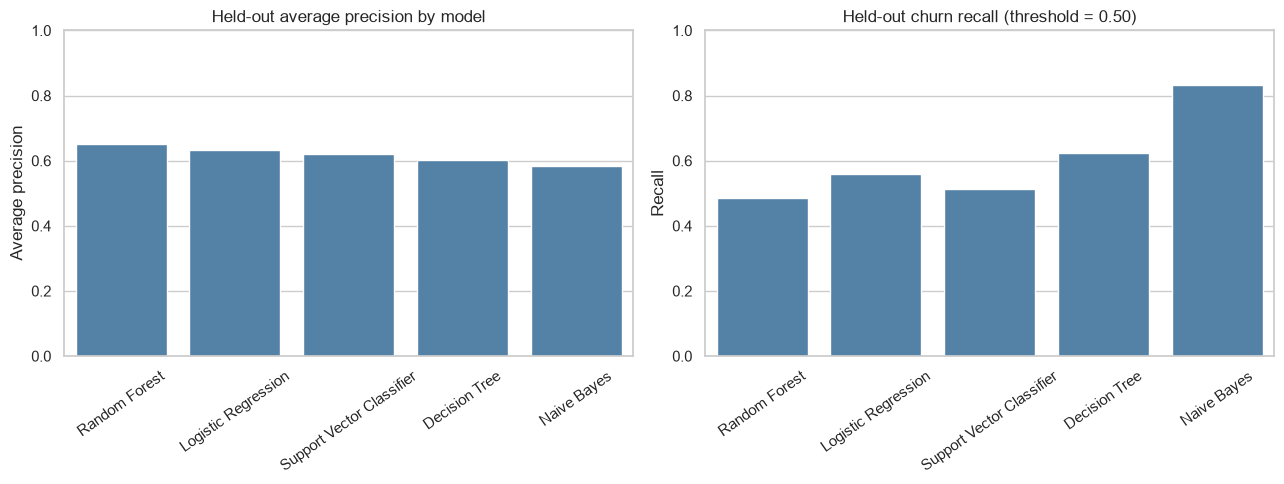

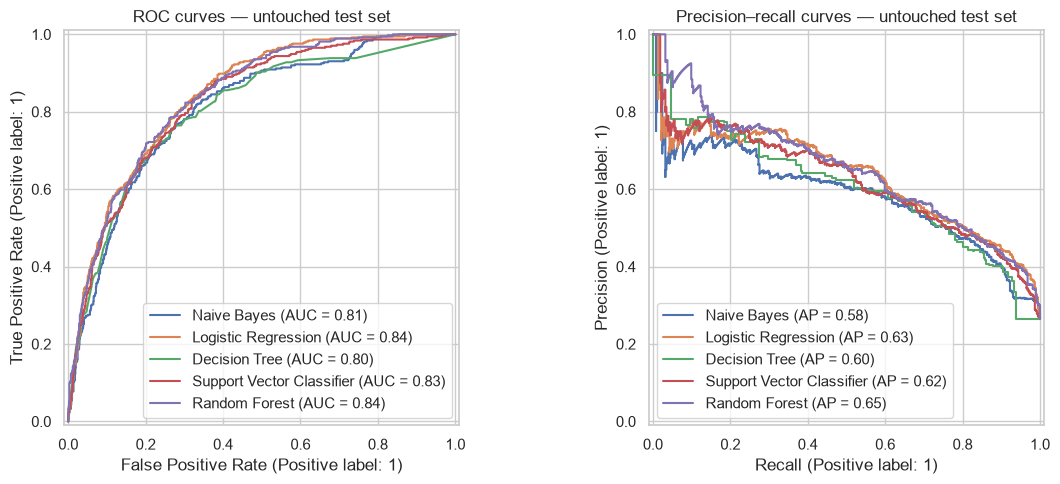

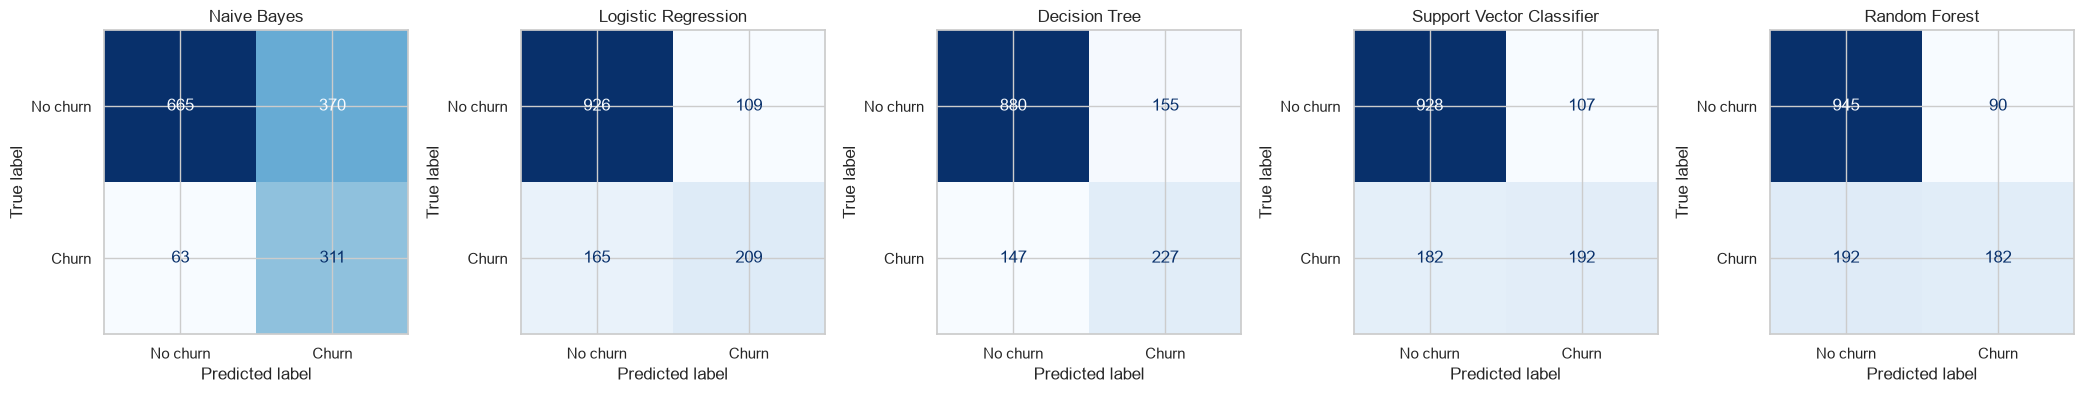

In [33]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
fig,axes=plt.subplots(1,2,figsize=(13,5))
order=test_results.sort_values('average_precision',ascending=False)
sns.barplot(data=order,x='model',y='average_precision',ax=axes[0],color='steelblue')
axes[0].set(title='Held-out average precision by model',xlabel='',ylabel='Average precision',ylim=(0,1))
sns.barplot(data=order,x='model',y='recall',ax=axes[1],color='steelblue')
axes[1].set(title='Held-out churn recall (threshold = 0.50)',xlabel='',ylabel='Recall',ylim=(0,1))
for ax in axes:ax.tick_params(axis='x',rotation=35)
fig.tight_layout();fig.savefig(FIG/'08_model_comparison.png',dpi=150,bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for name,est in best_estimators.items():
    RocCurveDisplay.from_estimator(est,X_test,y_test,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_estimator(est,X_test,y_test,ax=axes[1],name=name)
axes[0].set_title('ROC curves — untouched test set');axes[1].set_title('Precision–recall curves — untouched test set')
fig.tight_layout();fig.savefig(FIG/'09_roc_pr_comparison.png',dpi=150,bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,5,figsize=(21,4))
for ax,(name,est) in zip(axes,best_estimators.items()):
    ConfusionMatrixDisplay.from_estimator(est,X_test,y_test,ax=ax,cmap='Blues',colorbar=False,display_labels=['No churn','Churn']);ax.set_title(name)
fig.tight_layout();fig.savefig(FIG/'10_confusion_matrices.png',dpi=150,bbox_inches='tight');plt.show()

## Selecting the Best Model

The preferred classifier is the one with the highest **training-only cross-validation average precision**. Test-set results provide an unbiased descriptive comparison, but are not used to select a different winner. Review tradeoffs in recall, precision, interpretability, and cost of false alarms before considering any retention pilot.

## Conclusion and Future Work

Notebook 03 interprets the selected model, compares thresholds, and explains operational recommendations. These models predict association with churn, **not** whether an outreach action would prevent churn. External validation on SaaS renewal records and a controlled intervention experiment are needed.

### Results interpretation and operational considerations

The cross-validation winner is the *recommended research model*, not a production-ready retention system. Differences among classifiers should be judged alongside false negatives, false positives, interpretability, and outreach capacity. Do not choose a deployment probability threshold by optimizing the held-out test set.

In [34]:
# Compact, human-readable comparison generated from measured model results.
comparison = cv_results[['model', 'cv_average_precision']].merge(
    test_results[['model', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']],
    on='model', how='left'
).sort_values('cv_average_precision', ascending=False)
display(comparison.round(4))
print(f"Selected by training CV average precision: {selected}")
print('Highest holdout recall:', test_results.loc[test_results.recall.idxmax(), 'model'])
print('Highest holdout average precision:', test_results.loc[test_results.average_precision.idxmax(), 'model'])
print('These test-set rankings are descriptive and do not override the training-CV selection.')

,model,cv_average_precision,precision,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.6602,0.6572,0.5588,0.6040,0.8419,0.6334
1,Random Forest,0.6526,0.6691,0.4866,0.5635,0.8394,0.6502
2,Support Vector Classifier,0.6494,0.6421,0.5134,0.5706,0.8266,0.6211
3,Naive Bayes,0.6134,0.4567,0.8316,0.5896,0.8070,0.5846
4,Decision Tree,0.5903,0.5782,0.6230,0.5997,0.8048,0.6026


Selected by training CV average precision: Logistic Regression
Highest holdout recall: Naive Bayes
Highest holdout average precision: Random Forest
These test-set rankings are descriptive and do not override the training-CV selection.


## Notebook 01 — Summary and Next Steps

The training-only cross-validation ranking selects the final classifier. The held-out test metrics are presented as an evaluation, **not** as a reason to change the selected algorithm. Continue to [Notebook 02](Subscription_Churn_Evaluation.ipynb) for model statistics, individual customer predictions, global and local explanations, business insights, limitations, and future work.


## Overall Results and Business Implications

**Final model comparison:** The five classifiers above are compared using training-only cross-validation average precision for model selection. The held-out test results characterize performance, not a basis for selecting a different model. Logistic Regression is the selected model in this project. The findings below summarize the exploratory analysis and baseline observations; they are **not** claims that the five-model comparison independently established causal business effects.

Business actions such as targeted onboarding, service reviews, and retention outreach should be evaluated through controlled experiments and monitored for false positives, missed churners, and outreach capacity.

### Exploratory Data Analysis and Baseline Model Findings
### Measured findings
- **Overall churn:** 1,869 of 7,043 customers (26.54%).
- **Contract:** month-to-month customers had 42.71% churn, versus 11.27% for one-year contracts and 2.83% for two-year contracts.
- **Payment method:** electronic-check customers had 45.29% churn, compared with 15.24% for automatic credit-card payments.
- **Internet service:** fiber-optic customers had 41.89% churn, compared with 18.96% for DSL and 7.40% for customers without internet service.
- **Data quality:** 11 blank `TotalCharges` values were identified and handled with training-only median imputation; no duplicate customer IDs were detected.
- **Baseline held-out performance:** accuracy **0.8055**, precision **0.6572**, recall **0.5588**, F1 **0.6040**, ROC-AUC **0.8419**, and average precision **0.6334**.

### Interpretation
The baseline identifies approximately **55.9%** of churned customers at the default 0.50 threshold. This leaves meaningful room to evaluate alternative decision thresholds and outreach workload in future work. Observed segment differences are **associations**, not causal evidence that switching contracts or payment methods prevents churn.

### Operational implications to test
Review onboarding and customer-success support for short-tenure and month-to-month customers; investigate friction associated with electronic-check payment and fiber-optic service segments. Test interventions through a controlled pilot before claiming business impact.

### Limitations
This is observational, cross-sectional telecom data, **not** verified Salesforce renewal opportunities or SaaS renewals. The dataset does not establish when every predictor became available, and model generalization to future customers is unverified. Correlated predictors limit coefficient-level interpretation.

### Next Steps

With the exploratory data analysis, baseline modeling, five-model comparison, and final model selection completed, future work can focus on additional validation and practical application.

Potential next steps include evaluating alternative classification thresholds using training or validation data to balance precision and recall, estimating retention outreach capacity and operational costs, and validating performance on more recent, representative subscription renewal records.

Before any real-world deployment, the approach would also require monitoring for model drift and fairness issues, appropriate privacy safeguards, and controlled experiments to determine whether targeted retention interventions improve renewal outcomes.

## Final Conclusion and Future Work

The project progresses from data understanding and an interpretable Logistic Regression baseline to five separately tuned classifiers. The final research-model choice is based on **training-only cross-validation average precision**, with evaluation and individual customer explanations continued in **Notebook 02 — Subscription_Churn_Evaluation.ipynb**.

Next steps include threshold and outreach-capacity analysis using training/validation data, prospective monitoring, external validation on actual SaaS renewal records, fairness and drift checks, and controlled retention interventions. Associations in the IBM Telco dataset are not causal proof of which retention action will work.